In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve

In [45]:
data = pd.read_csv("data/BROWN-2006-2025.csv")
data = data.drop(columns = ["date"])
data["weather_code"] = (data["weather_code"] >= 51).astype(int)
p = 7
lagged = {}
for col in data.columns:
    for k in range(1, p + 1):
        lagged[col + "_lag" + str(k)] = data[col].shift(k)
X = pd.DataFrame(lagged).iloc[p:].reset_index(drop = True)

y = data["weather_code"].iloc[p:].reset_index(drop = True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts())

X shape: (6934, 133)
y shape: (6934,)
weather_code
0    3597
1    3337
Name: count, dtype: int64


In [46]:
X.head(10)

,weather_code_lag1,weather_code_lag2,weather_code_lag3,weather_code_lag4,weather_code_lag5,weather_code_lag6,weather_code_lag7,temperature_2m_mean_lag1,temperature_2m_mean_lag2,temperature_2m_mean_lag3,...,sunshine_duration_lag5,sunshine_duration_lag6,sunshine_duration_lag7,daylight_duration_lag1,daylight_duration_lag2,daylight_duration_lag3,daylight_duration_lag4,daylight_duration_lag5,daylight_duration_lag6,daylight_duration_lag7
0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,-2.162584,1.795750,1.874917,...,0.0000,25692.5590,13678.8870,33494.910,33430.016,33368.844,33311.200,33257.145,33206.742,33160.043
1,1.0,0.0,0.0,1.0,1.0,1.0,1.0,-0.270917,-2.162584,1.795750,...,23905.1210,0.0000,25692.5590,33564.200,33494.910,33430.016,33368.844,33311.200,33257.145,33206.742
2,0.0,1.0,0.0,0.0,1.0,1.0,1.0,3.860334,-0.270917,-2.162584,...,1047.6377,23905.1210,0.0000,33637.773,33564.200,33494.910,33430.016,33368.844,33311.200,33257.145
3,0.0,0.0,1.0,0.0,0.0,1.0,1.0,3.645751,3.860334,-0.270917,...,14390.3910,1047.6377,23905.1210,33715.477,33637.773,33564.200,33494.910,33430.016,33368.844,33311.200
4,1.0,0.0,0.0,1.0,0.0,0.0,1.0,5.512417,3.645751,3.860334,...,31951.9360,14390.3910,1047.6377,33797.120,33715.477,33637.773,33564.200,33494.910,33430.016,33368.844
5,1.0,1.0,0.0,0.0,1.0,0.0,0.0,8.935334,5.512417,3.645751,...,13919.3670,31951.9360,14390.3910,33882.560,33797.120,33715.477,33637.773,33564.200,33494.910,33430.016
6,0.0,1.0,1.0,0.0,0.0,1.0,0.0,6.022833,8.935334,5.512417,...,30317.9590,13919.3670,31951.9360,33971.605,33882.560,33797.120,33715.477,33637.773,33564.200,33494.910
7,1.0,0.0,1.0,1.0,0.0,0.0,1.0,11.589500,6.022833,8.935334,...,32614.4860,30317.9590,13919.3670,34064.098,33971.605,33882.560,33797.120,33715.477,33637.773,33564.200
8,1.0,1.0,0.0,1.0,1.0,0.0,0.0,-3.593833,11.589500,6.022833,...,9481.6740,32614.4860,30317.9590,34159.875,34064.098,33971.605,33882.560,33797.120,33715.477,33637.773
9,0.0,1.0,1.0,0.0,1.0,1.0,0.0,-7.352169,-3.593833,11.589500,...,32938.8120,9481.6740,32614.4860,34258.777,34159.875,34064.098,33971.605,33882.560,33797.120,33715.477


In [47]:
y.head(10)

0    1
1    0
2    0
3    1
4    1
5    0
6    1
7    1
8    0
9    0
Name: weather_code, dtype: int64

train log loss LogisticRegression: 0.601
test log loss LogisticRegression: 0.623
train accuracy LogisticRegression: 0.68
test accuracy LogisticRegression: 0.655


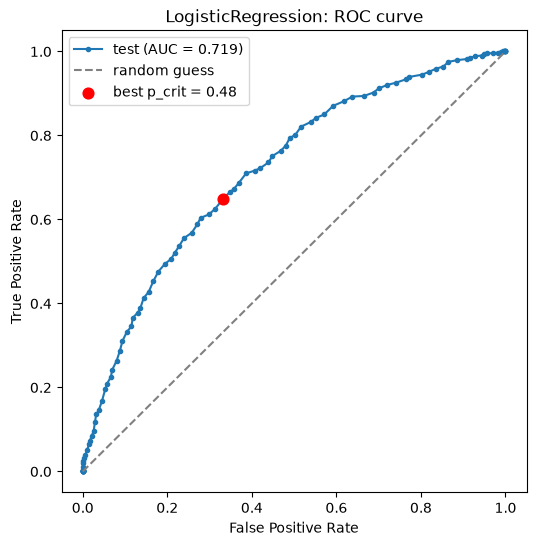

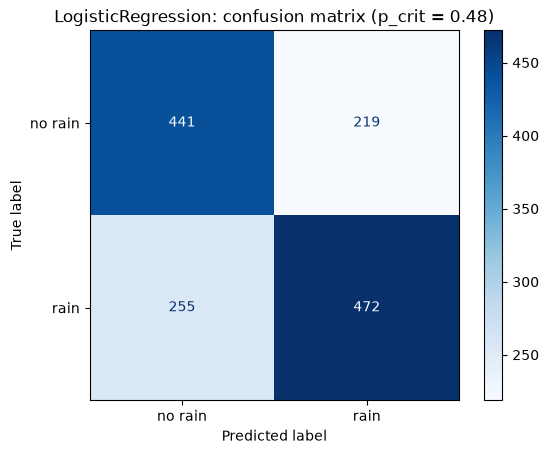

test ROC AUC LogisticRegression: 0.719
best p_crit LogisticRegression: 0.48


In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle = False)

bins = [c for c in X.columns if c.startswith("weather_code")]
cons = [c for c in X.columns if c not in bins]
preprocessor = ColumnTransformer([
    ('con', StandardScaler(), cons),
    ('bin', 'passthrough', bins)
])

pipe_logreg = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = None, max_iter = 10000))
])
pipe_logreg.fit(X_train, y_train)

print("train log loss LogisticRegression:", round(log_loss(y_train, pipe_logreg.predict_proba(X_train)[:, 1]), 3))
print("test log loss LogisticRegression:", round(log_loss(y_test, pipe_logreg.predict_proba(X_test)[:, 1]), 3))
print("train accuracy LogisticRegression:", round(accuracy_score(y_train, pipe_logreg.predict(X_train)), 3))
print("test accuracy LogisticRegression:", round(accuracy_score(y_test, pipe_logreg.predict(X_test)), 3))

y_test_prob = pipe_logreg.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_logreg = []
for p in p_crits:
    y_pred_p = (y_test_prob >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_logreg.append((fp / (fp + tn), tp / (tp + fn)))

auc_logreg = roc_auc_score(y_test, y_test_prob)
fpr_logreg, tpr_logreg = zip(*rocauc_logreg)

dist = np.sqrt(np.array(fpr_logreg) ** 2 + (1 - np.array(tpr_logreg)) ** 2)
best_idx_logreg = np.argmin(dist)
best_p_crit_logreg = p_crits[best_idx_logreg]

plt.figure(figsize = (6, 6))
plt.plot(fpr_logreg, tpr_logreg, marker = '.', label = 'test (AUC = ' + str(round(auc_logreg, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_logreg[best_idx_logreg], tpr_logreg[best_idx_logreg], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_logreg, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LogisticRegression: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob >= best_p_crit_logreg).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('LogisticRegression: confusion matrix (p_crit = ' + str(round(best_p_crit_logreg, 2)) + ')')
plt.show()

print("test ROC AUC LogisticRegression:", round(auc_logreg, 3))
print("best p_crit LogisticRegression:", round(best_p_crit_logreg, 2))

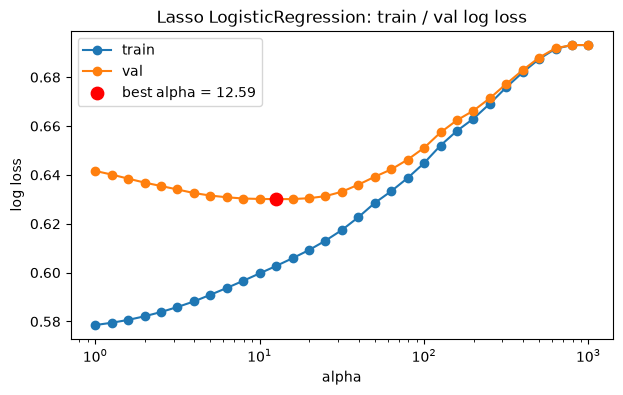

best alpha Lasso: 12.59
train log loss Lasso: 0.611
test log loss Lasso: 0.624
train accuracy Lasso: 0.673
test accuracy Lasso: 0.661


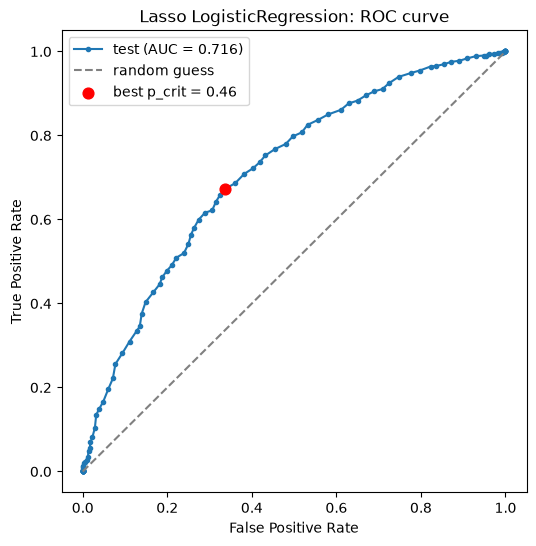

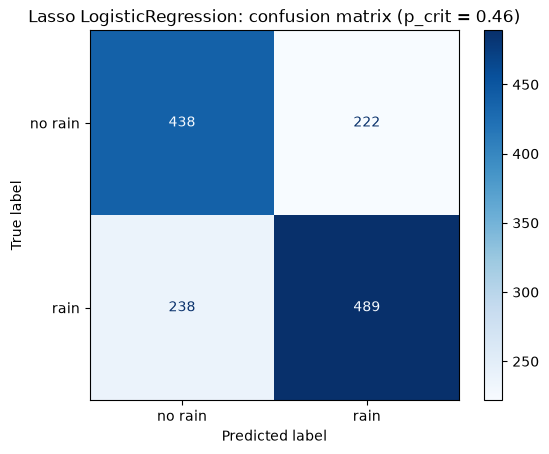

test ROC AUC Lasso: 0.716
best p_crit Lasso: 0.46


In [52]:
tss = TimeSeriesSplit(n_splits = 5)

alphas_lasso = np.logspace(0, 3, 31)
train_lasso = []
val_lasso = []
for a in alphas_lasso:
    train_scores = []
    val_scores = []
    for train_idx, val_idx in tss.split(X_train):
        pipe = Pipeline([
            ('prep', preprocessor),
            ('model', LogisticRegression(penalty = 'l1', solver = 'liblinear', C = 1 / a, max_iter = 10000))
        ])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
        val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
    train_lasso.append(np.mean(train_scores))
    val_lasso.append(np.mean(val_scores))

best_alpha_lasso = alphas_lasso[np.argmin(val_lasso)]

plt.figure(figsize = (7, 4))
plt.semilogx(alphas_lasso, train_lasso, marker = 'o', label = 'train')
plt.semilogx(alphas_lasso, val_lasso, marker = 'o', label = 'val')
plt.scatter(best_alpha_lasso, min(val_lasso), color = 'red', s = 80, zorder = 3, label = 'best alpha = ' + str(round(best_alpha_lasso, 2)))
plt.xlabel('alpha')
plt.ylabel('log loss')
plt.title('Lasso LogisticRegression: train / val log loss')
plt.legend()
plt.show()

pipe_lasso = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = 'l1', solver = 'liblinear', C = 1 / best_alpha_lasso, max_iter = 10000))
])
pipe_lasso.fit(X_train, y_train)

print("best alpha Lasso:", round(best_alpha_lasso, 2))
print("train log loss Lasso:", round(log_loss(y_train, pipe_lasso.predict_proba(X_train)[:, 1]), 3))
print("test log loss Lasso:", round(log_loss(y_test, pipe_lasso.predict_proba(X_test)[:, 1]), 3))
print("train accuracy Lasso:", round(accuracy_score(y_train, pipe_lasso.predict(X_train)), 3))
print("test accuracy Lasso:", round(accuracy_score(y_test, pipe_lasso.predict(X_test)), 3))

y_test_prob_lasso = pipe_lasso.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_lasso = []
for p in p_crits:
    y_pred_p = (y_test_prob_lasso >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_lasso.append((fp / (fp + tn), tp / (tp + fn)))

auc_lasso = roc_auc_score(y_test, y_test_prob_lasso)
fpr_lasso, tpr_lasso = zip(*rocauc_lasso)

dist = np.sqrt(np.array(fpr_lasso) ** 2 + (1 - np.array(tpr_lasso)) ** 2)
best_idx_lasso = np.argmin(dist)
best_p_crit_lasso = p_crits[best_idx_lasso]

plt.figure(figsize = (6, 6))
plt.plot(fpr_lasso, tpr_lasso, marker = '.', label = 'test (AUC = ' + str(round(auc_lasso, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_lasso[best_idx_lasso], tpr_lasso[best_idx_lasso], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_lasso, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Lasso LogisticRegression: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_lasso >= best_p_crit_lasso).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('Lasso LogisticRegression: confusion matrix (p_crit = ' + str(round(best_p_crit_lasso, 2)) + ')')
plt.show()

print("test ROC AUC Lasso:", round(auc_lasso, 3))
print("best p_crit Lasso:", round(best_p_crit_lasso, 2))

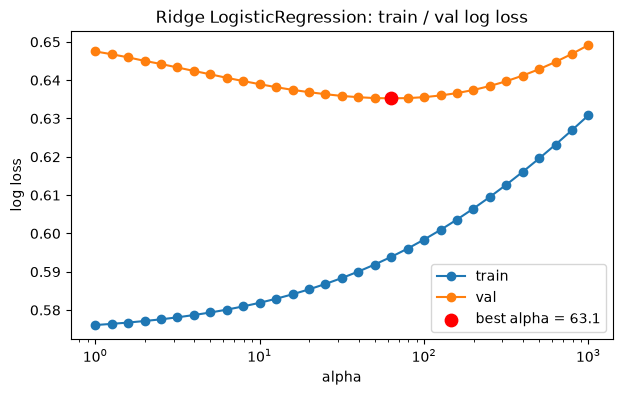

best alpha Ridge: 63.1
train log loss Ridge: 0.608
test log loss Ridge: 0.624
train accuracy Ridge: 0.678
test accuracy Ridge: 0.656


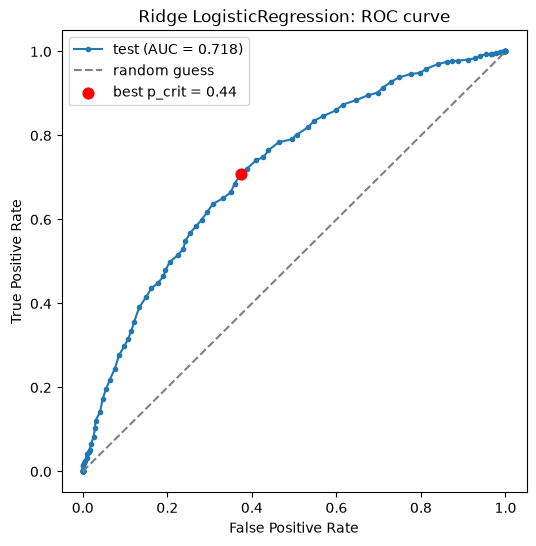

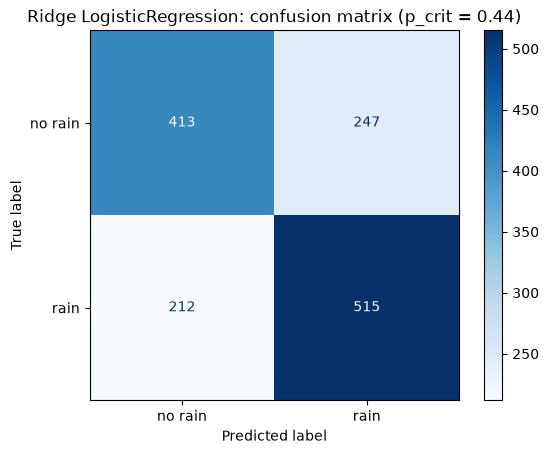

test ROC AUC Ridge: 0.718
best p_crit Ridge: 0.44


In [53]:
tss = TimeSeriesSplit(n_splits = 5)

alphas_ridge = np.logspace(0, 3, 31)
train_ridge = []
val_ridge = []
for a in alphas_ridge:
    train_scores = []
    val_scores = []
    for train_idx, val_idx in tss.split(X_train):
        pipe = Pipeline([
            ('prep', preprocessor),
            ('model', LogisticRegression(penalty = 'l2', C = 1 / a, max_iter = 10000))
        ])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
        val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
    train_ridge.append(np.mean(train_scores))
    val_ridge.append(np.mean(val_scores))

best_alpha_ridge = alphas_ridge[np.argmin(val_ridge)]

plt.figure(figsize = (7, 4))
plt.semilogx(alphas_ridge, train_ridge, marker = 'o', label = 'train')
plt.semilogx(alphas_ridge, val_ridge, marker = 'o', label = 'val')
plt.scatter(best_alpha_ridge, min(val_ridge), color = 'red', s = 80, zorder = 3, label = 'best alpha = ' + str(round(best_alpha_ridge, 2)))
plt.xlabel('alpha')
plt.ylabel('log loss')
plt.title('Ridge LogisticRegression: train / val log loss')
plt.legend()
plt.show()

pipe_ridge = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = 'l2', C = 1 / best_alpha_ridge, max_iter = 10000))
])
pipe_ridge.fit(X_train, y_train)

print("best alpha Ridge:", round(best_alpha_ridge, 2))
print("train log loss Ridge:", round(log_loss(y_train, pipe_ridge.predict_proba(X_train)[:, 1]), 3))
print("test log loss Ridge:", round(log_loss(y_test, pipe_ridge.predict_proba(X_test)[:, 1]), 3))
print("train accuracy Ridge:", round(accuracy_score(y_train, pipe_ridge.predict(X_train)), 3))
print("test accuracy Ridge:", round(accuracy_score(y_test, pipe_ridge.predict(X_test)), 3))

y_test_prob_ridge = pipe_ridge.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_ridge = []
for p in p_crits:
    y_pred_p = (y_test_prob_ridge >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_ridge.append((fp / (fp + tn), tp / (tp + fn)))

auc_ridge = roc_auc_score(y_test, y_test_prob_ridge)
fpr_ridge, tpr_ridge = zip(*rocauc_ridge)

dist = np.sqrt(np.array(fpr_ridge) ** 2 + (1 - np.array(tpr_ridge)) ** 2)
best_idx_ridge = np.argmin(dist)
best_p_crit_ridge = p_crits[best_idx_ridge]

plt.figure(figsize = (6, 6))
plt.plot(fpr_ridge, tpr_ridge, marker = '.', label = 'test (AUC = ' + str(round(auc_ridge, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_ridge[best_idx_ridge], tpr_ridge[best_idx_ridge], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_ridge, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Ridge LogisticRegression: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_ridge >= best_p_crit_ridge).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('Ridge LogisticRegression: confusion matrix (p_crit = ' + str(round(best_p_crit_ridge, 2)) + ')')
plt.show()

print("test ROC AUC Ridge:", round(auc_ridge, 3))
print("best p_crit Ridge:", round(best_p_crit_ridge, 2))

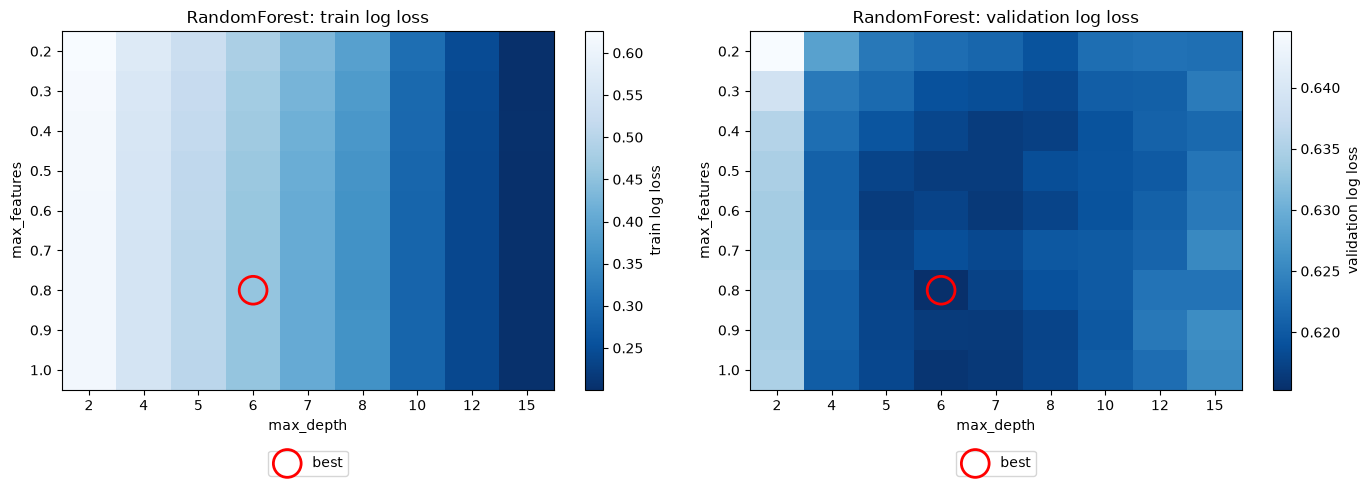

best max_features RandomForest: 0.8
best max_depth RandomForest: 6
train log loss RandomForest: 0.527
test log loss RandomForest: 0.615
train accuracy RandomForest: 0.749
test accuracy RandomForest: 0.662


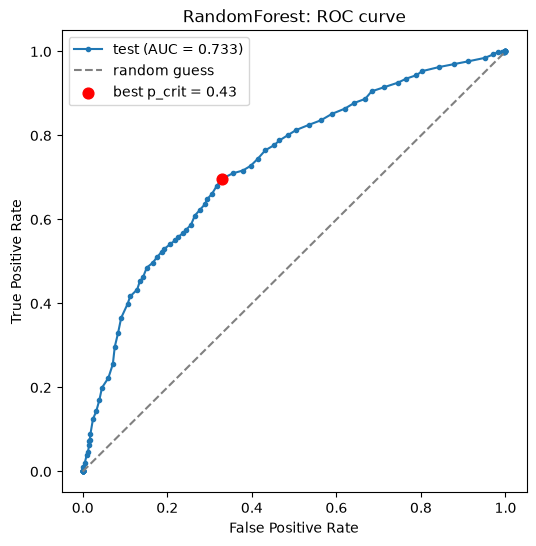

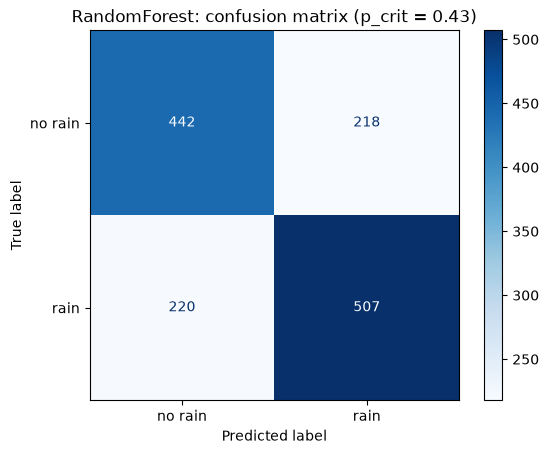

test ROC AUC RandomForest: 0.733
best p_crit RandomForest: 0.43


In [54]:
tss = TimeSeriesSplit(n_splits = 5)

max_features_rf = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
max_depths_rf = [2, 4, 5, 6, 7, 8, 10, 12, 15]
train_rf = np.zeros((len(max_features_rf), len(max_depths_rf)))
val_rf = np.zeros((len(max_features_rf), len(max_depths_rf)))
for i, mf in enumerate(max_features_rf):
    for j, d in enumerate(max_depths_rf):
        train_scores = []
        val_scores = []
        for train_idx, val_idx in tss.split(X_train):
            pipe = Pipeline([
                ('prep', preprocessor),
                ('model', RandomForestClassifier(n_estimators = 100, max_depth = d, max_features = mf, random_state = 42, n_jobs = -1))
            ])
            pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
            train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
            val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
        train_rf[i, j] = np.mean(train_scores)
        val_rf[i, j] = np.mean(val_scores)

best_i_rf, best_j_rf = np.unravel_index(np.argmin(val_rf), val_rf.shape)
best_max_features_rf = max_features_rf[best_i_rf]
best_max_depth_rf = max_depths_rf[best_j_rf]

fig, axes = plt.subplots(1, 2, figsize = (14, 5))
for ax, heat, panel in [(axes[0], train_rf, 'train'), (axes[1], val_rf, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = panel + ' log loss')
    ax.scatter(best_j_rf, best_i_rf, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(max_depths_rf)))
    ax.set_xticklabels(max_depths_rf)
    ax.set_yticks(range(len(max_features_rf)))
    ax.set_yticklabels(max_features_rf)
    ax.set_xlabel('max_depth')
    ax.set_ylabel('max_features')
    ax.set_title('RandomForest: ' + panel + ' log loss')
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.15))
plt.tight_layout()
plt.show()

pipe_rf = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators = 100, max_depth = best_max_depth_rf, max_features = best_max_features_rf, random_state = 42, n_jobs = -1))
])
pipe_rf.fit(X_train, y_train)

print("best max_features RandomForest:", best_max_features_rf)
print("best max_depth RandomForest:", best_max_depth_rf)
print("train log loss RandomForest:", round(log_loss(y_train, pipe_rf.predict_proba(X_train)[:, 1]), 3))
print("test log loss RandomForest:", round(log_loss(y_test, pipe_rf.predict_proba(X_test)[:, 1]), 3))
print("train accuracy RandomForest:", round(accuracy_score(y_train, pipe_rf.predict(X_train)), 3))
print("test accuracy RandomForest:", round(accuracy_score(y_test, pipe_rf.predict(X_test)), 3))

y_test_prob_rf = pipe_rf.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_rf = []
for p in p_crits:
    y_pred_p = (y_test_prob_rf >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_rf.append((fp / (fp + tn), tp / (tp + fn)))

auc_rf = roc_auc_score(y_test, y_test_prob_rf)
fpr_rf, tpr_rf = zip(*rocauc_rf)

dist = np.sqrt(np.array(fpr_rf) ** 2 + (1 - np.array(tpr_rf)) ** 2)
best_idx_rf = np.argmin(dist)
best_p_crit_rf = p_crits[best_idx_rf]

plt.figure(figsize = (6, 6))
plt.plot(fpr_rf, tpr_rf, marker = '.', label = 'test (AUC = ' + str(round(auc_rf, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_rf[best_idx_rf], tpr_rf[best_idx_rf], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_rf, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('RandomForest: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_rf >= best_p_crit_rf).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('RandomForest: confusion matrix (p_crit = ' + str(round(best_p_crit_rf, 2)) + ')')
plt.show()

print("test ROC AUC RandomForest:", round(auc_rf, 3))
print("best p_crit RandomForest:", round(best_p_crit_rf, 2))

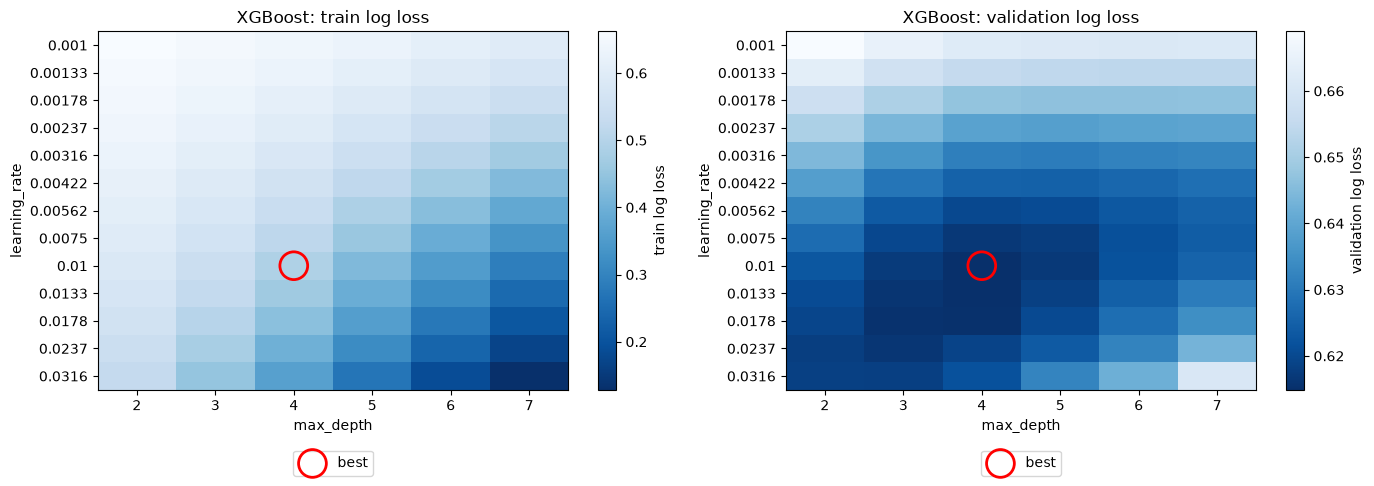

best learning_rate XGBoost: 0.01
best max_depth XGBoost: 4
train log loss XGBoost: 0.55
test log loss XGBoost: 0.61
train accuracy XGBoost: 0.727
test accuracy XGBoost: 0.675


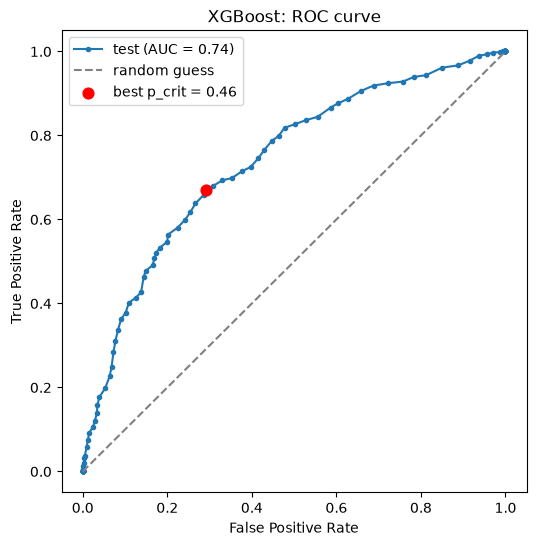

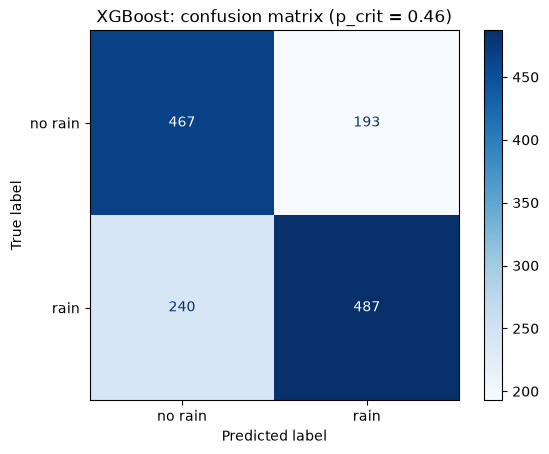

test ROC AUC XGBoost: 0.74
best p_crit XGBoost: 0.46


In [56]:
tss = TimeSeriesSplit(n_splits = 5)

learning_rates_xgb = np.logspace(-3, -1.5, 13)
max_depths_xgb = [2, 3, 4, 5, 6, 7]
train_xgb = np.zeros((len(learning_rates_xgb), len(max_depths_xgb)))
val_xgb = np.zeros((len(learning_rates_xgb), len(max_depths_xgb)))
for i, lr in enumerate(learning_rates_xgb):
    for j, d in enumerate(max_depths_xgb):
        train_scores = []
        val_scores = []
        for train_idx, val_idx in tss.split(X_train):
            pipe = Pipeline([
                ('prep', preprocessor),
                ('model', XGBClassifier(n_estimators = 300, learning_rate = lr, max_depth = d, random_state = 42, n_jobs = -1))
            ])
            pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
            train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
            val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
        train_xgb[i, j] = np.mean(train_scores)
        val_xgb[i, j] = np.mean(val_scores)

best_i_xgb, best_j_xgb = np.unravel_index(np.argmin(val_xgb), val_xgb.shape)
best_learning_rate_xgb = learning_rates_xgb[best_i_xgb]
best_max_depth_xgb = max_depths_xgb[best_j_xgb]

fig, axes = plt.subplots(1, 2, figsize = (14, 5))
for ax, heat, panel in [(axes[0], train_xgb, 'train'), (axes[1], val_xgb, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = panel + ' log loss')
    ax.scatter(best_j_xgb, best_i_xgb, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(max_depths_xgb)))
    ax.set_xticklabels(max_depths_xgb)
    ax.set_yticks(range(len(learning_rates_xgb)))
    ax.set_yticklabels(['%.3g' % v for v in learning_rates_xgb])
    ax.set_xlabel('max_depth')
    ax.set_ylabel('learning_rate')
    ax.set_title('XGBoost: ' + panel + ' log loss')
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.15))
plt.tight_layout()
plt.show()

pipe_xgb = Pipeline([
    ('prep', preprocessor),
    ('model', XGBClassifier(n_estimators = 300, learning_rate = best_learning_rate_xgb, max_depth = best_max_depth_xgb, random_state = 42, n_jobs = -1))
])
pipe_xgb.fit(X_train, y_train)

print("best learning_rate XGBoost:", round(best_learning_rate_xgb, 4))
print("best max_depth XGBoost:", best_max_depth_xgb)
print("train log loss XGBoost:", round(log_loss(y_train, pipe_xgb.predict_proba(X_train)[:, 1]), 3))
print("test log loss XGBoost:", round(log_loss(y_test, pipe_xgb.predict_proba(X_test)[:, 1]), 3))
print("train accuracy XGBoost:", round(accuracy_score(y_train, pipe_xgb.predict(X_train)), 3))
print("test accuracy XGBoost:", round(accuracy_score(y_test, pipe_xgb.predict(X_test)), 3))

y_test_prob_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_xgb = []
for p in p_crits:
    y_pred_p = (y_test_prob_xgb >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_xgb.append((fp / (fp + tn), tp / (tp + fn)))

auc_xgb = roc_auc_score(y_test, y_test_prob_xgb)
fpr_xgb, tpr_xgb = zip(*rocauc_xgb)

dist = np.sqrt(np.array(fpr_xgb) ** 2 + (1 - np.array(tpr_xgb)) ** 2)
best_idx_xgb = np.argmin(dist)
best_p_crit_xgb = p_crits[best_idx_xgb]

plt.figure(figsize = (6, 6))
plt.plot(fpr_xgb, tpr_xgb, marker = '.', label = 'test (AUC = ' + str(round(auc_xgb, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_xgb[best_idx_xgb], tpr_xgb[best_idx_xgb], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_xgb, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_xgb >= best_p_crit_xgb).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('XGBoost: confusion matrix (p_crit = ' + str(round(best_p_crit_xgb, 2)) + ')')
plt.show()

print("test ROC AUC XGBoost:", round(auc_xgb, 3))
print("best p_crit XGBoost:", round(best_p_crit_xgb, 2))

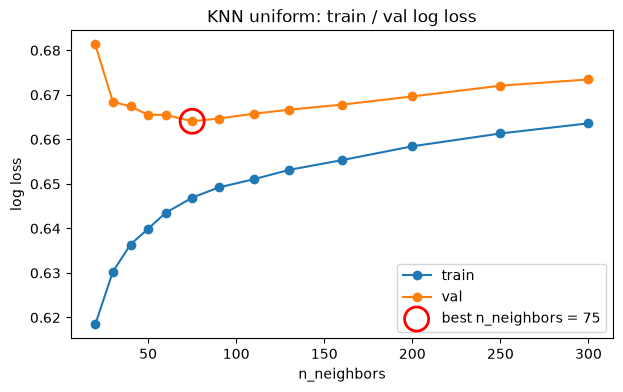

best n_neighbors KNN uniform: 75
train log loss KNN uniform: 0.647
test log loss KNN uniform: 0.66
train accuracy KNN uniform: 0.636
test accuracy KNN uniform: 0.605


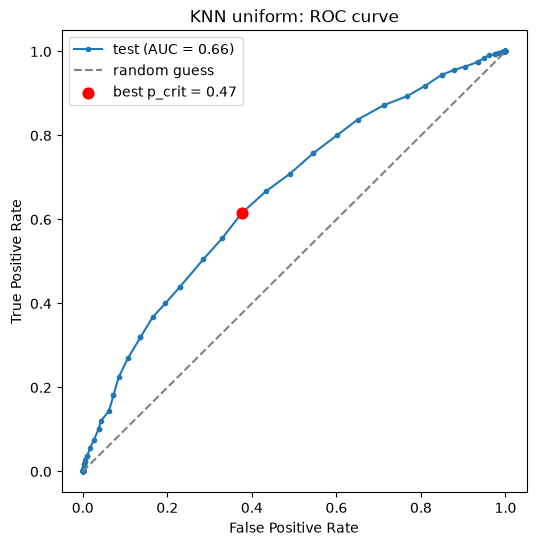

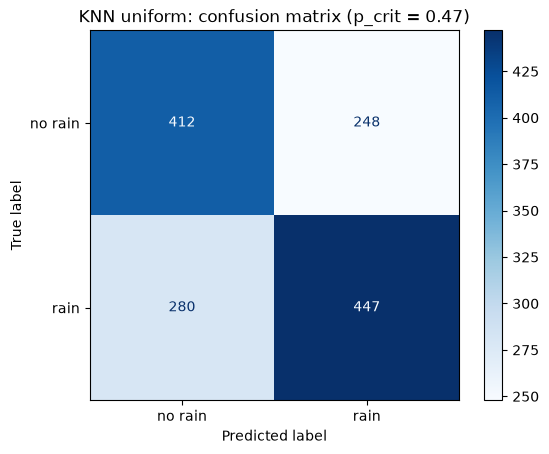

test ROC AUC KNN uniform: 0.66
best p_crit KNN uniform: 0.47


In [57]:
tss = TimeSeriesSplit(n_splits = 5)

n_neighbors_knn_uniform = [20, 30, 40, 50, 60, 75, 90, 110, 130, 160, 200, 250, 300]
train_knn_uniform = []
val_knn_uniform = []
for k in n_neighbors_knn_uniform:
    train_scores = []
    val_scores = []
    for train_idx, val_idx in tss.split(X_train):
        pipe = Pipeline([
            ('prep', preprocessor),
            ('model', KNeighborsClassifier(n_neighbors = k, weights = 'uniform', n_jobs = -1))
        ])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
        val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
    train_knn_uniform.append(np.mean(train_scores))
    val_knn_uniform.append(np.mean(val_scores))

best_n_neighbors_knn_uniform = n_neighbors_knn_uniform[np.argmin(val_knn_uniform)]

plt.figure(figsize = (7, 4))
plt.plot(n_neighbors_knn_uniform, train_knn_uniform, marker = 'o', label = 'train')
plt.plot(n_neighbors_knn_uniform, val_knn_uniform, marker = 'o', label = 'val')
plt.scatter(best_n_neighbors_knn_uniform, min(val_knn_uniform), s = 300, facecolors = 'none', edgecolors = 'red', linewidths = 2, zorder = 3, label = 'best n_neighbors = ' + str(best_n_neighbors_knn_uniform))
plt.xlabel('n_neighbors')
plt.ylabel('log loss')
plt.title('KNN uniform: train / val log loss')
plt.legend()
plt.show()

pipe_knn_uniform = Pipeline([
    ('prep', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors = best_n_neighbors_knn_uniform, weights = 'uniform', n_jobs = -1))
])
pipe_knn_uniform.fit(X_train, y_train)

print("best n_neighbors KNN uniform:", best_n_neighbors_knn_uniform)
print("train log loss KNN uniform:", round(log_loss(y_train, pipe_knn_uniform.predict_proba(X_train)[:, 1]), 3))
print("test log loss KNN uniform:", round(log_loss(y_test, pipe_knn_uniform.predict_proba(X_test)[:, 1]), 3))
print("train accuracy KNN uniform:", round(accuracy_score(y_train, pipe_knn_uniform.predict(X_train)), 3))
print("test accuracy KNN uniform:", round(accuracy_score(y_test, pipe_knn_uniform.predict(X_test)), 3))

y_test_prob_knn_uniform = pipe_knn_uniform.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_knn_uniform = []
for p in p_crits:
    y_pred_p = (y_test_prob_knn_uniform >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_knn_uniform.append((fp / (fp + tn), tp / (tp + fn)))

auc_knn_uniform = roc_auc_score(y_test, y_test_prob_knn_uniform)
fpr_knn_uniform, tpr_knn_uniform = zip(*rocauc_knn_uniform)

dist = np.sqrt(np.array(fpr_knn_uniform) ** 2 + (1 - np.array(tpr_knn_uniform)) ** 2)
best_idx_knn_uniform = np.argmin(dist)
best_p_crit_knn_uniform = p_crits[best_idx_knn_uniform]

plt.figure(figsize = (6, 6))
plt.plot(fpr_knn_uniform, tpr_knn_uniform, marker = '.', label = 'test (AUC = ' + str(round(auc_knn_uniform, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_knn_uniform[best_idx_knn_uniform], tpr_knn_uniform[best_idx_knn_uniform], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_knn_uniform, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('KNN uniform: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_knn_uniform >= best_p_crit_knn_uniform).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('KNN uniform: confusion matrix (p_crit = ' + str(round(best_p_crit_knn_uniform, 2)) + ')')
plt.show()

print("test ROC AUC KNN uniform:", round(auc_knn_uniform, 3))
print("best p_crit KNN uniform:", round(best_p_crit_knn_uniform, 2))

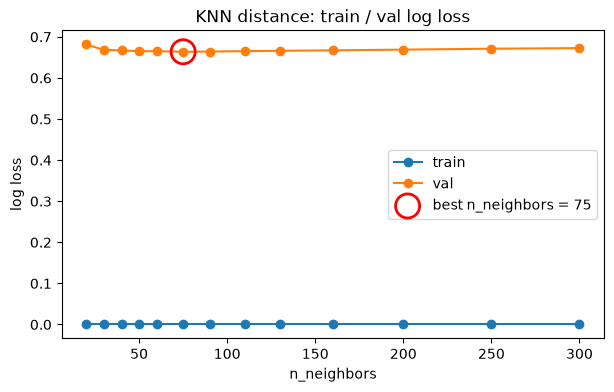

best n_neighbors KNN distance: 75
train log loss KNN distance: 0.0
test log loss KNN distance: 0.66
train accuracy KNN distance: 1.0
test accuracy KNN distance: 0.604


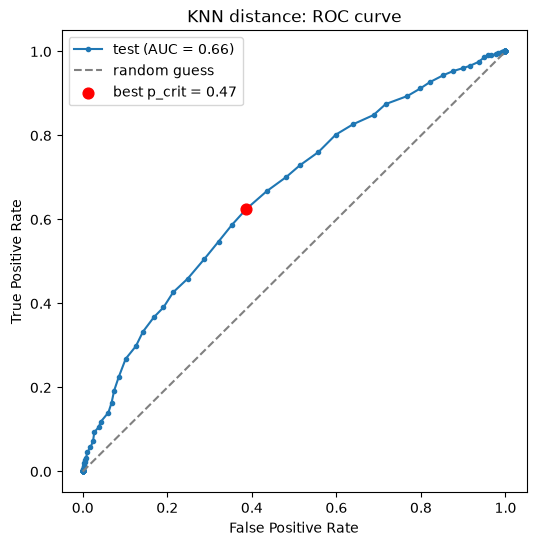

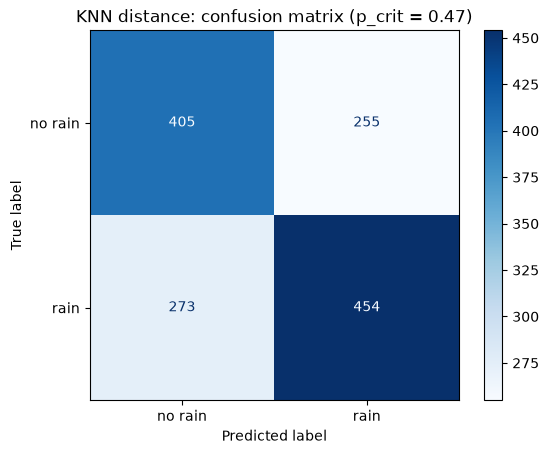

test ROC AUC KNN distance: 0.66
best p_crit KNN distance: 0.47


In [58]:
tss = TimeSeriesSplit(n_splits = 5)

n_neighbors_knn_distance = [20, 30, 40, 50, 60, 75, 90, 110, 130, 160, 200, 250, 300]
train_knn_distance = []
val_knn_distance = []
for k in n_neighbors_knn_distance:
    train_scores = []
    val_scores = []
    for train_idx, val_idx in tss.split(X_train):
        pipe = Pipeline([
            ('prep', preprocessor),
            ('model', KNeighborsClassifier(n_neighbors = k, weights = 'distance', n_jobs = -1))
        ])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
        val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
    train_knn_distance.append(np.mean(train_scores))
    val_knn_distance.append(np.mean(val_scores))

best_n_neighbors_knn_distance = n_neighbors_knn_distance[np.argmin(val_knn_distance)]

plt.figure(figsize = (7, 4))
plt.plot(n_neighbors_knn_distance, train_knn_distance, marker = 'o', label = 'train')
plt.plot(n_neighbors_knn_distance, val_knn_distance, marker = 'o', label = 'val')
plt.scatter(best_n_neighbors_knn_distance, min(val_knn_distance), s = 300, facecolors = 'none', edgecolors = 'red', linewidths = 2, zorder = 3, label = 'best n_neighbors = ' + str(best_n_neighbors_knn_distance))
plt.xlabel('n_neighbors')
plt.ylabel('log loss')
plt.title('KNN distance: train / val log loss')
plt.legend()
plt.show()

pipe_knn_distance = Pipeline([
    ('prep', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors = best_n_neighbors_knn_distance, weights = 'distance', n_jobs = -1))
])
pipe_knn_distance.fit(X_train, y_train)

print("best n_neighbors KNN distance:", best_n_neighbors_knn_distance)
print("train log loss KNN distance:", round(log_loss(y_train, pipe_knn_distance.predict_proba(X_train)[:, 1]), 3))
print("test log loss KNN distance:", round(log_loss(y_test, pipe_knn_distance.predict_proba(X_test)[:, 1]), 3))
print("train accuracy KNN distance:", round(accuracy_score(y_train, pipe_knn_distance.predict(X_train)), 3))
print("test accuracy KNN distance:", round(accuracy_score(y_test, pipe_knn_distance.predict(X_test)), 3))

y_test_prob_knn_distance = pipe_knn_distance.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_knn_distance = []
for p in p_crits:
    y_pred_p = (y_test_prob_knn_distance >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_knn_distance.append((fp / (fp + tn), tp / (tp + fn)))

auc_knn_distance = roc_auc_score(y_test, y_test_prob_knn_distance)
fpr_knn_distance, tpr_knn_distance = zip(*rocauc_knn_distance)

dist = np.sqrt(np.array(fpr_knn_distance) ** 2 + (1 - np.array(tpr_knn_distance)) ** 2)
best_idx_knn_distance = np.argmin(dist)
best_p_crit_knn_distance = p_crits[best_idx_knn_distance]

plt.figure(figsize = (6, 6))
plt.plot(fpr_knn_distance, tpr_knn_distance, marker = '.', label = 'test (AUC = ' + str(round(auc_knn_distance, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_knn_distance[best_idx_knn_distance], tpr_knn_distance[best_idx_knn_distance], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_knn_distance, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('KNN distance: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_knn_distance >= best_p_crit_knn_distance).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('KNN distance: confusion matrix (p_crit = ' + str(round(best_p_crit_knn_distance, 2)) + ')')
plt.show()

print("test ROC AUC KNN distance:", round(auc_knn_distance, 3))
print("best p_crit KNN distance:", round(best_p_crit_knn_distance, 2))

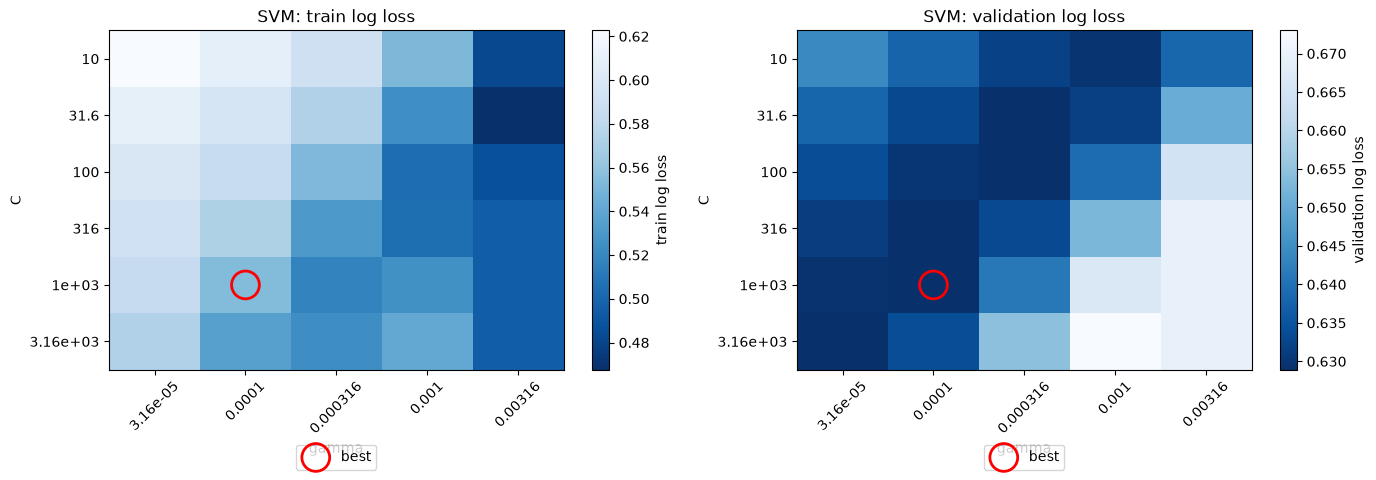

best C SVM: 1000.0
best gamma SVM: 0.0001
train log loss SVM: 0.567
test log loss SVM: 0.614
train accuracy SVM: 0.721
test accuracy SVM: 0.666


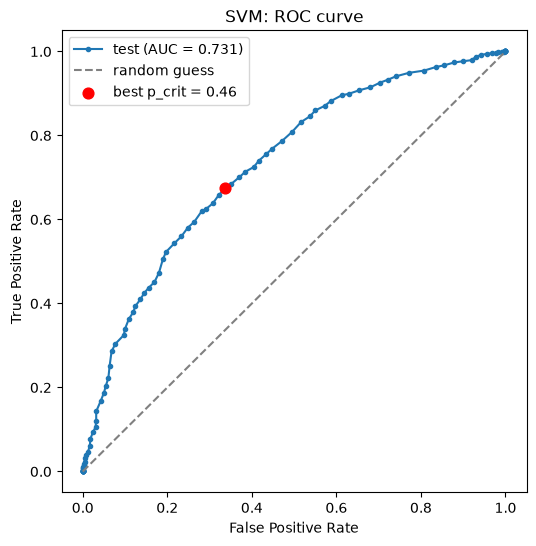

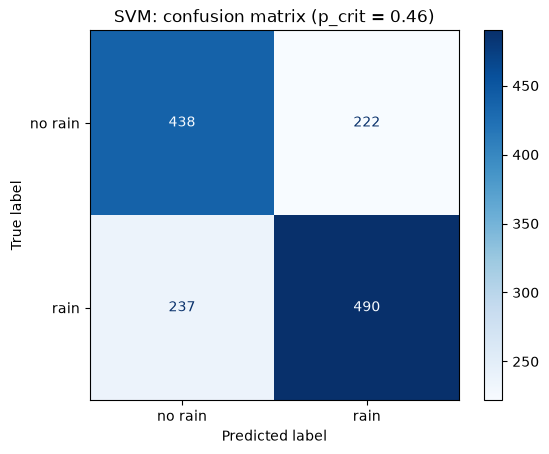

test ROC AUC SVM: 0.731
best p_crit SVM: 0.46


In [73]:
tss = TimeSeriesSplit(n_splits = 5)
Cs_svm = np.logspace(1, 3.5, 6)

gammas_svm = np.logspace(-4.5, -2.5, 5)
train_svm = np.zeros((len(Cs_svm), len(gammas_svm)))
val_svm = np.zeros((len(Cs_svm), len(gammas_svm)))
for i, c in enumerate(Cs_svm):
    for j, g in enumerate(gammas_svm):
        train_scores = []
        val_scores = []
        for train_idx, val_idx in tss.split(X_train):
            pipe = Pipeline([
                ('prep', preprocessor),
                ('model', SVC(C = c, gamma = g, probability = True, random_state = 42))
            ])
            pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
            train_scores.append(log_loss(y_train.iloc[train_idx], pipe.predict_proba(X_train.iloc[train_idx])[:, 1]))
            val_scores.append(log_loss(y_train.iloc[val_idx], pipe.predict_proba(X_train.iloc[val_idx])[:, 1]))
        train_svm[i, j] = np.mean(train_scores)
        val_svm[i, j] = np.mean(val_scores)

best_i_svm, best_j_svm = np.unravel_index(np.argmin(val_svm), val_svm.shape)
best_C_svm = Cs_svm[best_i_svm]
best_gamma_svm = gammas_svm[best_j_svm]

fig, axes = plt.subplots(1, 2, figsize = (14, 5))
for ax, heat, panel in [(axes[0], train_svm, 'train'), (axes[1], val_svm, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = panel + ' log loss')
    ax.scatter(best_j_svm, best_i_svm, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(gammas_svm)))
    ax.set_xticklabels(['%.3g' % v for v in gammas_svm], rotation = 45)
    ax.set_yticks(range(len(Cs_svm)))
    ax.set_yticklabels(['%.3g' % v for v in Cs_svm])
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
    ax.set_title('SVM: ' + panel + ' log loss')
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
plt.tight_layout()
plt.show()

pipe_svm = Pipeline([
    ('prep', preprocessor),
    ('model', SVC(C = best_C_svm, gamma = best_gamma_svm, probability = True, random_state = 42))
])
pipe_svm.fit(X_train, y_train)

print("best C SVM:", round(best_C_svm, 3))
print("best gamma SVM:", round(best_gamma_svm, 6))
print("train log loss SVM:", round(log_loss(y_train, pipe_svm.predict_proba(X_train)[:, 1]), 3))
print("test log loss SVM:", round(log_loss(y_test, pipe_svm.predict_proba(X_test)[:, 1]), 3))
print("train accuracy SVM:", round(accuracy_score(y_train, pipe_svm.predict(X_train)), 3))
print("test accuracy SVM:", round(accuracy_score(y_test, pipe_svm.predict(X_test)), 3))

y_test_prob_svm = pipe_svm.predict_proba(X_test)[:, 1]

p_crits = np.linspace(0, 1, 101)

rocauc_svm = []
for p in p_crits:
    y_pred_p = (y_test_prob_svm >= p).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_p, labels = [0, 1]).ravel()
    rocauc_svm.append((fp / (fp + tn), tp / (tp + fn)))

auc_svm = roc_auc_score(y_test, y_test_prob_svm)
fpr_svm, tpr_svm = zip(*rocauc_svm)

dist = np.sqrt(np.array(fpr_svm) ** 2 + (1 - np.array(tpr_svm)) ** 2)
best_idx_svm = np.argmin(dist)
best_p_crit_svm = p_crits[best_idx_svm]

plt.figure(figsize = (6, 6))
plt.plot(fpr_svm, tpr_svm, marker = '.', label = 'test (AUC = ' + str(round(auc_svm, 3)) + ')')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'random guess')
plt.scatter(fpr_svm[best_idx_svm], tpr_svm[best_idx_svm], color = 'red', s = 60, zorder = 3, label = 'best p_crit = ' + str(round(best_p_crit_svm, 2)))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SVM: ROC curve')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, (y_test_prob_svm >= best_p_crit_svm).astype(int), labels = [0, 1])
ConfusionMatrixDisplay(cm, display_labels = ['no rain', 'rain']).plot(cmap = 'Blues')
plt.title('SVM: confusion matrix (p_crit = ' + str(round(best_p_crit_svm, 2)) + ')')
plt.show()

print("test ROC AUC SVM:", round(auc_svm, 3))
print("best p_crit SVM:", round(best_p_crit_svm, 2))


In [74]:
from sklearn.metrics import precision_score, recall_score

best_p_crit = {
    'LogisticRegression': best_p_crit_logreg,
    'Ridge': best_p_crit_ridge,
    'Lasso': best_p_crit_lasso,
    'RandomForest': best_p_crit_rf,
    'XGBoost': best_p_crit_xgb,
    'KNN uniform': best_p_crit_knn_uniform,
    'KNN distance': best_p_crit_knn_distance,
    'SVM': best_p_crit_svm
}

best_params = {
    'LogisticRegression': {'penalty': None},
    'Ridge': {'alpha': best_alpha_ridge},
    'Lasso': {'alpha': best_alpha_lasso},
    'RandomForest': {'max_depth': best_max_depth_rf, 'max_features': best_max_features_rf},
    'XGBoost': {'max_depth': best_max_depth_xgb, 'learning_rate': best_learning_rate_xgb},
    'KNN uniform': {'n_neighbors': best_n_neighbors_knn_uniform},
    'KNN distance': {'n_neighbors': best_n_neighbors_knn_distance},
    'SVM': {'C': best_C_svm, 'gamma': best_gamma_svm}
}

y_test_prob_all = {
    'LogisticRegression': y_test_prob,
    'Ridge': y_test_prob_ridge,
    'Lasso': y_test_prob_lasso,
    'RandomForest': y_test_prob_rf,
    'XGBoost': y_test_prob_xgb,
    'KNN uniform': y_test_prob_knn_uniform,
    'KNN distance': y_test_prob_knn_distance,
    'SVM': y_test_prob_svm
}

y_pred = {}
for m in best_p_crit:
    y_pred[m] = (y_test_prob_all[m] >= best_p_crit[m]).astype(int)

cm = {}
for m in y_pred:
    cm[m] = confusion_matrix(y_test, y_pred[m], labels = [0, 1])

roc_auc = {
    'LogisticRegression': rocauc_logreg,
    'Ridge': rocauc_ridge,
    'Lasso': rocauc_lasso,
    'RandomForest': rocauc_rf,
    'XGBoost': rocauc_xgb,
    'KNN uniform': rocauc_knn_uniform,
    'KNN distance': rocauc_knn_distance,
    'SVM': rocauc_svm
}

accuracy = {}
precision = {}
recall = {}
f1 = {}
for m in y_pred:
    accuracy[m] = accuracy_score(y_test, y_pred[m])
    precision[m] = precision_score(y_test, y_pred[m])
    recall[m] = recall_score(y_test, y_pred[m])
    f1[m] = f1_score(y_test, y_pred[m])

library = {
    'best_p_crit': best_p_crit,
    'best_params': best_params,
    'cm': cm,
    'roc_auc': roc_auc,
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'f1': f1
}

In [75]:
y_pred['general baseline'] = np.ones(len(y_test), dtype = int)
y_pred['yesterday baseline'] = X_test['weather_code_lag1'].astype(int).values

best_params['general baseline'] = 'always predict rain'
best_params['yesterday baseline'] = 'rain yesterday -> rain today, weather_code_lag1'
best_p_crit['general baseline'] = np.nan
best_p_crit['yesterday baseline'] = np.nan

for m in ['general baseline', 'yesterday baseline']:
    cm[m] = confusion_matrix(y_test, y_pred[m], labels = [0, 1])
    accuracy[m] = accuracy_score(y_test, y_pred[m])
    precision[m] = precision_score(y_test, y_pred[m])
    recall[m] = recall_score(y_test, y_pred[m])
    f1[m] = f1_score(y_test, y_pred[m])

In [76]:
param_meaning = {
    'LogisticRegression': 'no hyperparameter, no penalty',
    'Ridge': 'alpha: L2 penalty strength, C = 1 / alpha, shrinks all coefficients',
    'Lasso': 'alpha: L1 penalty strength, C = 1 / alpha, can set coefficients to 0',
    'RandomForest': 'max_depth: max depth of each tree; max_features: fraction of features tried at each split',
    'XGBoost': 'max_depth: max depth of each tree; learning_rate: how much each new tree corrects',
    'KNN uniform': 'n_neighbors: number of neighbors, every neighbor votes equally',
    'KNN distance': 'n_neighbors: number of neighbors, closer neighbors vote more',
    'SVM': 'C: penalty on misclassified points; gamma: RBF kernel width, larger = more local',
    'general baseline': 'no model, always predict rain (1)',
    'yesterday baseline': 'no model, rain yesterday -> predict rain today (weather_code_lag1)'
}

In [77]:
results_accuracy = pd.DataFrame({
    'best_params': best_params,
    'param_meaning': param_meaning,
    'best_p_crit': best_p_crit,
    'accuracy': accuracy
})
results_accuracy['accuracy'] = results_accuracy['accuracy'].round(3)
results_accuracy = results_accuracy.sort_values('accuracy', ascending = False)
results_accuracy

,best_params,param_meaning,best_p_crit,accuracy
XGBoost,"{'max_depth': 4, 'learning_rate': 0.01}",max_depth: max depth of each tree; learning_ra...,0.46,0.688
RandomForest,"{'max_depth': 6, 'max_features': 0.8}",max_depth: max depth of each tree; max_feature...,0.43,0.684
Ridge,{'alpha': 63.09573444801933},"alpha: L2 penalty strength, C = 1 / alpha, shr...",0.44,0.669
SVM,"{'C': 1000.0, 'gamma': 0.0001}",C: penalty on misclassified points; gamma: RBF...,0.46,0.669
Lasso,{'alpha': 12.589254117941675},"alpha: L1 penalty strength, C = 1 / alpha, can...",0.46,0.668
LogisticRegression,{'penalty': None},"no hyperparameter, no penalty",0.48,0.658
KNN uniform,{'n_neighbors': 75},"n_neighbors: number of neighbors, every neighb...",0.47,0.619
KNN distance,{'n_neighbors': 75},"n_neighbors: number of neighbors, closer neigh...",0.47,0.619
yesterday baseline,"rain yesterday -> rain today, weather_code_lag1","no model, rain yesterday -> predict rain today...",NaN,0.596
general baseline,always predict rain,"no model, always predict rain (1)",NaN,0.524


In [78]:
results_precision = pd.DataFrame({
    'best_params': best_params,
    'param_meaning': param_meaning,
    'best_p_crit': best_p_crit,
    'precision': precision
})
results_precision['precision'] = results_precision['precision'].round(3)
results_precision = results_precision.sort_values('precision', ascending = False)
results_precision

,best_params,param_meaning,best_p_crit,precision
XGBoost,"{'max_depth': 4, 'learning_rate': 0.01}",max_depth: max depth of each tree; learning_ra...,0.46,0.716
RandomForest,"{'max_depth': 6, 'max_features': 0.8}",max_depth: max depth of each tree; max_feature...,0.43,0.699
Lasso,{'alpha': 12.589254117941675},"alpha: L1 penalty strength, C = 1 / alpha, can...",0.46,0.688
SVM,"{'C': 1000.0, 'gamma': 0.0001}",C: penalty on misclassified points; gamma: RBF...,0.46,0.688
LogisticRegression,{'penalty': None},"no hyperparameter, no penalty",0.48,0.683
Ridge,{'alpha': 63.09573444801933},"alpha: L2 penalty strength, C = 1 / alpha, shr...",0.44,0.676
KNN uniform,{'n_neighbors': 75},"n_neighbors: number of neighbors, every neighb...",0.47,0.643
KNN distance,{'n_neighbors': 75},"n_neighbors: number of neighbors, closer neigh...",0.47,0.640
yesterday baseline,"rain yesterday -> rain today, weather_code_lag1","no model, rain yesterday -> predict rain today...",NaN,0.614
general baseline,always predict rain,"no model, always predict rain (1)",NaN,0.524


In [79]:
results_recall = pd.DataFrame({
    'best_params': best_params,
    'param_meaning': param_meaning,
    'best_p_crit': best_p_crit,
    'recall': recall
})
results_recall['recall'] = results_recall['recall'].round(3)
results_recall = results_recall.sort_values('recall', ascending = False)
results_recall

,best_params,param_meaning,best_p_crit,recall
general baseline,always predict rain,"no model, always predict rain (1)",NaN,1.000
Ridge,{'alpha': 63.09573444801933},"alpha: L2 penalty strength, C = 1 / alpha, shr...",0.44,0.708
RandomForest,"{'max_depth': 6, 'max_features': 0.8}",max_depth: max depth of each tree; max_feature...,0.43,0.697
SVM,"{'C': 1000.0, 'gamma': 0.0001}",C: penalty on misclassified points; gamma: RBF...,0.46,0.674
Lasso,{'alpha': 12.589254117941675},"alpha: L1 penalty strength, C = 1 / alpha, can...",0.46,0.673
XGBoost,"{'max_depth': 4, 'learning_rate': 0.01}",max_depth: max depth of each tree; learning_ra...,0.46,0.670
LogisticRegression,{'penalty': None},"no hyperparameter, no penalty",0.48,0.649
KNN distance,{'n_neighbors': 75},"n_neighbors: number of neighbors, closer neigh...",0.47,0.624
KNN uniform,{'n_neighbors': 75},"n_neighbors: number of neighbors, every neighb...",0.47,0.615
yesterday baseline,"rain yesterday -> rain today, weather_code_lag1","no model, rain yesterday -> predict rain today...",NaN,0.613


In [80]:
results_f1 = pd.DataFrame({
    'best_params': best_params,
    'param_meaning': param_meaning,
    'best_p_crit': best_p_crit,
    'f1': f1
})
results_f1['f1'] = results_f1['f1'].round(3)
results_f1 = results_f1.sort_values('f1', ascending = False)
results_f1

,best_params,param_meaning,best_p_crit,f1
RandomForest,"{'max_depth': 6, 'max_features': 0.8}",max_depth: max depth of each tree; max_feature...,0.43,0.698
Ridge,{'alpha': 63.09573444801933},"alpha: L2 penalty strength, C = 1 / alpha, shr...",0.44,0.692
XGBoost,"{'max_depth': 4, 'learning_rate': 0.01}",max_depth: max depth of each tree; learning_ra...,0.46,0.692
general baseline,always predict rain,"no model, always predict rain (1)",NaN,0.688
SVM,"{'C': 1000.0, 'gamma': 0.0001}",C: penalty on misclassified points; gamma: RBF...,0.46,0.681
Lasso,{'alpha': 12.589254117941675},"alpha: L1 penalty strength, C = 1 / alpha, can...",0.46,0.680
LogisticRegression,{'penalty': None},"no hyperparameter, no penalty",0.48,0.666
KNN distance,{'n_neighbors': 75},"n_neighbors: number of neighbors, closer neigh...",0.47,0.632
KNN uniform,{'n_neighbors': 75},"n_neighbors: number of neighbors, every neighb...",0.47,0.629
yesterday baseline,"rain yesterday -> rain today, weather_code_lag1","no model, rain yesterday -> predict rain today...",NaN,0.614


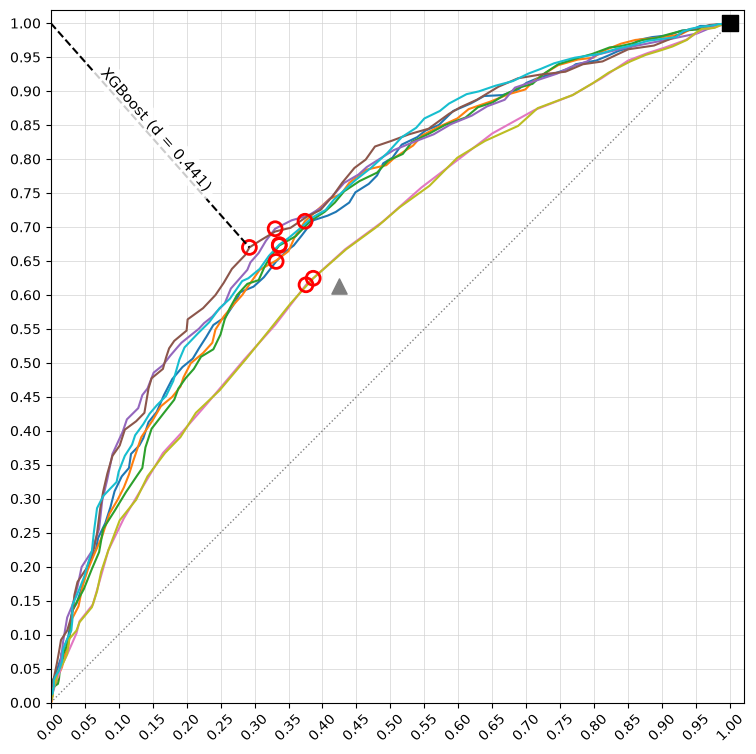

closest to (0, 1): XGBoost
distance: 0.441
best p_crit: 0.46


In [87]:
models = ['LogisticRegression', 'Ridge', 'Lasso', 'RandomForest', 'XGBoost', 'KNN uniform', 'KNN distance', 'SVM']
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive', 'tab:cyan']
best_dist = []
best_fpr = []
best_tpr = []

plt.figure(figsize = (9, 9))
for m, c in zip(models, colors):
    fpr_m, tpr_m = zip(*roc_auc[m])
    fpr_m = np.array(fpr_m)
    tpr_m = np.array(tpr_m)
    dist_m = np.sqrt(fpr_m ** 2 + (1 - tpr_m) ** 2)
    idx_m = np.argmin(dist_m)
    best_dist.append(dist_m[idx_m])
    best_fpr.append(fpr_m[idx_m])
    best_tpr.append(tpr_m[idx_m])
    auc_m = roc_auc_score(y_test, y_test_prob_all[m])
    plt.plot(fpr_m, tpr_m, color = c, linewidth = 1.5, label = m + ' (AUC = ' + str(round(auc_m, 3)) + ')')
    plt.scatter(fpr_m[idx_m], tpr_m[idx_m], s = 100, facecolors = 'none', edgecolors = 'red', linewidths = 2, zorder = 3)

for m, c, mk in [('yesterday baseline', 'tab:gray', '^'), ('general baseline', 'black', 's')]:
    tn, fp, fn, tp = cm[m].ravel()
    plt.scatter(fp / (fp + tn), tp / (tp + fn), s = 120, color = c, marker = mk, zorder = 4, label = m)

plt.scatter([], [], s = 100, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best p_crit')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = ':', linewidth = 1, label = 'random guess')

k = np.argmin(best_dist)
closest_model = models[k]
bx = best_fpr[k]
by = best_tpr[k]
plt.plot([0, bx], [1, by], color = 'black', linestyle = '--', linewidth = 1.5, zorder = 4)
angle = np.degrees(np.arctan2(by - 1, bx))
plt.text(bx / 2, (1 + by) / 2, closest_model + ' (d = ' + str(round(best_dist[k], 3)) + ')', rotation = angle, rotation_mode = 'anchor', ha = 'center', va = 'bottom', fontsize = 11, zorder = 5, bbox = dict(facecolor = 'white', edgecolor = 'none', alpha = 0.8))

plt.gca().set_aspect('equal')
plt.xlim(0, 1.02)
plt.ylim(0, 1.02)
plt.xticks(np.arange(0, 1.01, 0.05), rotation = 45)
plt.yticks(np.arange(0, 1.01, 0.05))
plt.grid(color = 'lightgray', linewidth = 0.5)

plt.show()

print("closest to (0, 1):", closest_model)
print("distance:", round(best_dist[k], 3))
print("best p_crit:", best_p_crit[closest_model])

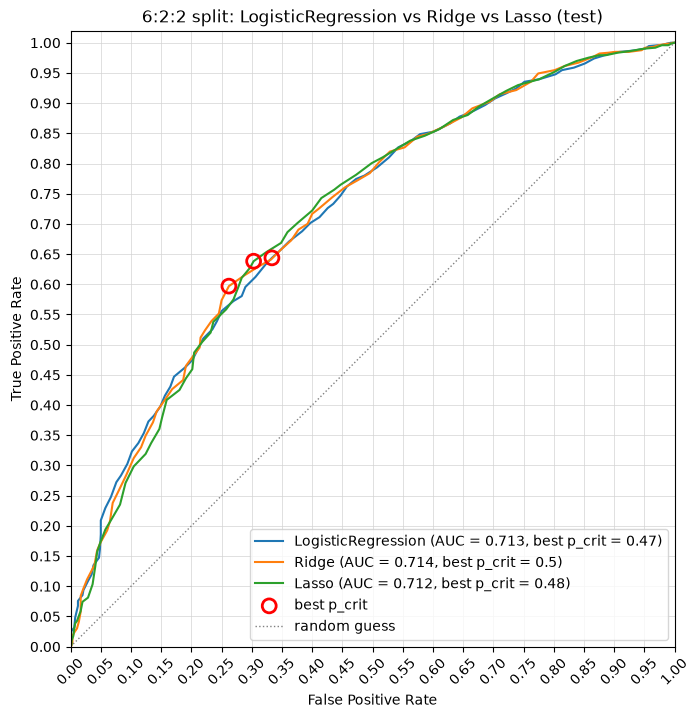

,model,best alpha,val log loss,test log loss,test accuracy
0,Ridge,39.811,0.637,0.627,0.664
1,Lasso,15.849,0.634,0.627,0.661
2,LogisticRegression,NaN,NaN,0.630,0.650


In [89]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size = 0.25, shuffle = False)

pipe_logreg_split = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = None, max_iter = 10000))
])
pipe_logreg_split.fit(X_tr, y_tr)

alphas_ridge_split = np.logspace(0, 3, 31)
val_ridge_split = []
for a in alphas_ridge_split:
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(penalty = 'l2', C = 1 / a, max_iter = 10000))
    ])
    pipe.fit(X_tr, y_tr)
    val_ridge_split.append(log_loss(y_val, pipe.predict_proba(X_val)[:, 1]))
best_alpha_ridge_split = alphas_ridge_split[np.argmin(val_ridge_split)]

pipe_ridge_split = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = 'l2', C = 1 / best_alpha_ridge_split, max_iter = 10000))
])
pipe_ridge_split.fit(X_tr, y_tr)

alphas_lasso_split = np.logspace(0, 3, 31)
val_lasso_split = []
for a in alphas_lasso_split:
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(penalty = 'l1', solver = 'liblinear', C = 1 / a, max_iter = 10000))
    ])
    pipe.fit(X_tr, y_tr)
    val_lasso_split.append(log_loss(y_val, pipe.predict_proba(X_val)[:, 1]))
best_alpha_lasso_split = alphas_lasso_split[np.argmin(val_lasso_split)]

pipe_lasso_split = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty = 'l1', solver = 'liblinear', C = 1 / best_alpha_lasso_split, max_iter = 10000))
])
pipe_lasso_split.fit(X_tr, y_tr)

pipes_split = {
    'LogisticRegression': pipe_logreg_split,
    'Ridge': pipe_ridge_split,
    'Lasso': pipe_lasso_split
}
colors_split = ['tab:blue', 'tab:orange', 'tab:green']
p_crits = np.linspace(0, 1, 101)

plt.figure(figsize = (8, 8))
for m, c in zip(pipes_split, colors_split):
    y_test_prob_m = pipes_split[m].predict_proba(X_test)[:, 1]
    fpr_m = []
    tpr_m = []
    for p in p_crits:
        tn, fp, fn, tp = confusion_matrix(y_test, (y_test_prob_m >= p).astype(int), labels = [0, 1]).ravel()
        fpr_m.append(fp / (fp + tn))
        tpr_m.append(tp / (tp + fn))
    fpr_m = np.array(fpr_m)
    tpr_m = np.array(tpr_m)
    idx_m = np.argmin(np.sqrt(fpr_m ** 2 + (1 - tpr_m) ** 2))
    plt.plot(fpr_m, tpr_m, color = c, linewidth = 1.5, label = m + ' (AUC = ' + str(round(roc_auc_score(y_test, y_test_prob_m), 3)) + ', best p_crit = ' + str(round(p_crits[idx_m], 2)) + ')')
    plt.scatter(fpr_m[idx_m], tpr_m[idx_m], s = 100, facecolors = 'none', edgecolors = 'red', linewidths = 2, zorder = 3)

plt.scatter([], [], s = 100, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best p_crit')
plt.plot([0, 1], [0, 1], color = 'gray', linestyle = ':', linewidth = 1, label = 'random guess')
plt.gca().set_aspect('equal')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.xticks(np.arange(0, 1.01, 0.05), rotation = 45)
plt.yticks(np.arange(0, 1.01, 0.05))
plt.grid(color = 'lightgray', linewidth = 0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('6:2:2 split: LogisticRegression vs Ridge vs Lasso (test)')
plt.legend(loc = 'lower right')
plt.show()

rows = [
    ['LogisticRegression', np.nan, np.nan, log_loss(y_test, pipe_logreg_split.predict_proba(X_test)[:, 1]), accuracy_score(y_test, pipe_logreg_split.predict(X_test))],
    ['Ridge', best_alpha_ridge_split, min(val_ridge_split), log_loss(y_test, pipe_ridge_split.predict_proba(X_test)[:, 1]), accuracy_score(y_test, pipe_ridge_split.predict(X_test))],
    ['Lasso', best_alpha_lasso_split, min(val_lasso_split), log_loss(y_test, pipe_lasso_split.predict_proba(X_test)[:, 1]), accuracy_score(y_test, pipe_lasso_split.predict(X_test))]
]

score_split = pd.DataFrame(rows, columns = ['model', 'best alpha', 'val log loss', 'test log loss', 'test accuracy'])
score_split = score_split.round(3).sort_values('test accuracy', ascending = False).reset_index(drop = True)
score_split